# Demonstration
This Jupyter notebooks is designed as a tutorial and visual demonstration of the inherent explainability of basic statistical and machine-learning models.

In [1]:
from __future__ import print_function
import numpy as np
import pandas as pd
import seaborn as sns
from importlib import reload
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score,f1_score, accuracy_score,mean_squared_error,mean_absolute_error)
from sklearn import metrics
from sklearn.preprocessing import Normalizer, LabelEncoder, StandardScaler, OneHotEncoder,Binarizer
from sklearn.utils import class_weight

## Data prep.

In [2]:
traindata = pd.read_csv('/kaggle/input/unsw-nb15/UNSW_NB15_training-set.csv')
testdata = pd.read_csv('/kaggle/input/unsw-nb15/UNSW_NB15_testing-set.csv')
traindata = traindata.drop('id', axis=1)
testdata = testdata.drop('id', axis=1)
print(traindata.shape, testdata.shape)

(82332, 44) (175341, 44)


In [3]:
traindata['service'].replace('-',np.nan,inplace=True)
testdata['service'].replace('-',np.nan,inplace=True)
print(traindata['service'].isna().sum()) # 47153 out of 82332
print(testdata['service'].isna().sum()) # 94168 out of 175341

47153
94168


In [4]:
traindata = traindata.drop(['service'],axis=1)
testdata = testdata.drop(['service'],axis=1)

In [5]:
def transfer_num_to_log(df):
    conv = []
    df_numeric = df.select_dtypes(include=[np.number])
    for feature in df_numeric.columns:
        if df_numeric[feature].nunique()>50:
            conv.append(feature)
            if df_numeric[feature].min()==0:
                df[feature] = np.log(df[feature]+1)
            else:
                df[feature] = np.log(df[feature])
    print("converted: ",conv)
    return df

traindata_log = transfer_num_to_log(traindata)
testdata_log = transfer_num_to_log(testdata)

converted:  ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'response_body_len', 'ct_srv_src', 'ct_dst_src_ltm', 'ct_srv_dst']
converted:  ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'response_body_len', 'ct_srv_src', 'ct_dst_src_ltm', 'ct_srv_dst']


In [6]:
for c in range(1,4):
    traindata.iloc[:,c] = LabelEncoder().fit_transform(traindata.iloc[:,c])
    testdata.iloc[:,c] = LabelEncoder().fit_transform(testdata.iloc[:,c])
    
from sklearn.model_selection import train_test_split
# Use last column for stratification (binary label)
traindata, _ = train_test_split(
    traindata,
    test_size=0.90,  # Keep 10%
    stratify=traindata.iloc[:, -1],  # Stratify on binary label
    random_state=42  # For reproducibility
)

train_x = traindata.iloc[:,0:41]
train_y_b = traindata.iloc[:,-1]
train_y_m = traindata.iloc[:,-2]
test_x = testdata.iloc[:,0:41]
test_y_b = testdata.iloc[:,-1]
test_y_m = testdata.iloc[:,-2]

## XAI Integration of DL-based Techniques

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

class CNN_DNN_BinaryClassifier(nn.Module):
    def __init__(self, input_channels, input_length):
        super().__init__()
        # 1D CNN Layer
        self.conv1 = nn.Conv1d(in_channels=input_channels, out_channels=16, kernel_size=3)
        self.pool = nn.MaxPool1d(kernel_size=2)
        # Dynamically compute flattened size
        after_conv = (input_length - 2) // 2
        self.fc1 = nn.Linear(16 * after_conv, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
    
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)  # flatten
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x.squeeze()

In [8]:
train_x = train_x.values
train_y_b = train_y_b.values
test_x = test_x.values
test_y_b = test_y_b.values

print("After .values conversion:")
print(type(train_x), type(train_y_b), type(test_x), type(test_y_b))

train_x_tensor = torch.tensor(train_x, dtype=torch.float32).unsqueeze(1)  
test_x_tensor  = torch.tensor(test_x, dtype=torch.float32).unsqueeze(1)

train_y_tensor = torch.tensor(train_y_b, dtype=torch.float32)
test_y_tensor  = torch.tensor(test_y_b, dtype=torch.float32)

# Create PyTorch datasets
train_dataset = TensorDataset(train_x_tensor, train_y_tensor)
test_dataset  = TensorDataset(test_x_tensor, test_y_tensor)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

After .values conversion:
<class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [11]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

model = CNN_DNN_BinaryClassifier(input_channels=1, input_length=41)  
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

criterion = nn.BCELoss()  
scheduler = ReduceLROnPlateau(optimizer,
                              mode='min',        
                              factor=0.5,        
                              patience=5,        
                              verbose=True,
                              min_lr=1e-7)

for epoch in range(30):
    model.train()
    for data, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(data.float())  
        loss = criterion(outputs, labels.float())
        loss.backward()
        optimizer.step()

## XAI Techniques and Implementation
### SHAP
* Install: pip install shap
* Usage with PyTorch: Supports DeepExplainer

We use the first 100 test records for the SHAP background and 10 records for explanation.

In [13]:
import shap
background = test_x_tensor[:100]      
test_samples = test_x_tensor[100:110]

print(background.shape)   
print(test_samples.shape) 

torch.Size([100, 1, 41])
torch.Size([10, 1, 41])


In [14]:
model.eval()

device = next(model.parameters()).device
background = background.to(device)       # torch.Size([100, 1, 41])
test_samples = test_samples.to(device)   # torch.Size([10, 1, 41])

class ShapWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        out = self.model(x)
        if out.ndim == 1:          # (B,)
            out = out.unsqueeze(1) # (B, 1)
        return out

wrapped_model = ShapWrapper(model).eval()

explainer = shap.DeepExplainer(wrapped_model, background)
shap_vals = explainer.shap_values(test_samples)

Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.


Once we have the SHAP values, we can plot a global summary plot.

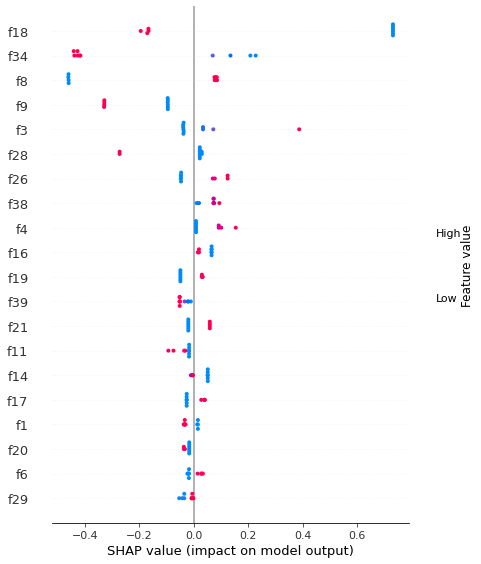

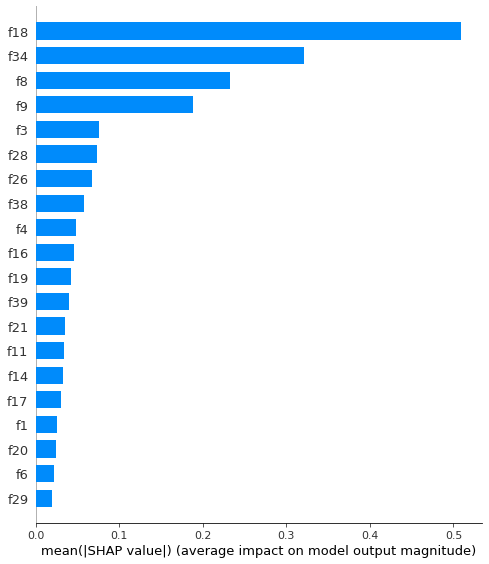

In [15]:
if isinstance(shap_vals, list):
    shap_vals_arr = shap_vals[0]   
else:
    shap_vals_arr = shap_vals

X = test_samples.detach().cpu().numpy().squeeze(1)          # (B, 41)
S = np.array(shap_vals_arr).squeeze(1)                      # (B, 41)
feature_names = [f"f{i}" for i in range(X.shape[1])]

shap.summary_plot(S, X, feature_names=feature_names)        # beeswarm
shap.summary_plot(S, X, feature_names=feature_names, plot_type="bar")  # mean(|SHAP|)

### LIME

* pip install lime

LIME expects tabular input, so we need train_x.

In [16]:
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

n_features = train_x.shape[1]
feature_names = [f"f{i}" for i in range(n_features)]
model.eval()
device = next(model.parameters()).device  # works for CPU/GPU

@torch.no_grad()
def lime_predict_proba(x_2d_np: np.ndarray) -> np.ndarray:
    """
    Input:  (B, F) numpy from LIME
    Output: (B, 2) probabilities for [class0, class1]
    """
    x = torch.tensor(x_2d_np, dtype=torch.float32, device=device).unsqueeze(1)  # (B, 1, F)
    out = model(x)

    # Make shape (B,)
    out = out.squeeze()

    # Convert to probabilities for class 1
    # If your model already returns probabilities, keep it as-is.
    # If your model returns logits, apply sigmoid:
    p1 = torch.sigmoid(out)  # use this if model outputs logits

    p1 = p1.detach().cpu().numpy().reshape(-1)
    p0 = 1.0 - p1
    return np.vstack([p0, p1]).T  # (B, 2)


Create the LIME explainer.

In [18]:
explainer = LimeTabularExplainer(
    training_data=train_x,                 # 2D numpy
    feature_names=feature_names,
    class_names=["0", "1"],                # labels
    mode="classification",
    discretize_continuous=True             # usually helpful for tabular
)

Explain a single test instance.

In [19]:
i = 0  # pick a test row
x_instance = test_x[i]  # shape (41,)

exp = explainer.explain_instance(
    data_row=x_instance,
    predict_fn=lime_predict_proba,
    num_features=10,        
    num_samples=5000      
)

print(exp.as_list())      

[('0.00 < f18 <= 255.00', -0.11223283218197974), ('f9 > 252.00', 0.067372530206172), ('62.00 < f8 <= 254.00', 0.05225353021622536), ('f34 <= 0.00', 0.034014370960496074), ('0.00 < f21 <= 255.00', 0.03381788606862905), ('f32 <= 1.00', -0.030388516570256822), ('f33 <= 1.00', -0.023845450922019923), ('f35 <= 0.00', 0.01194188894006156), ('f36 <= 0.00', -0.01151216749811722), ('3.40 < f7 <= 7.87', -0.00755706229859999)]


Plot the local explanation.

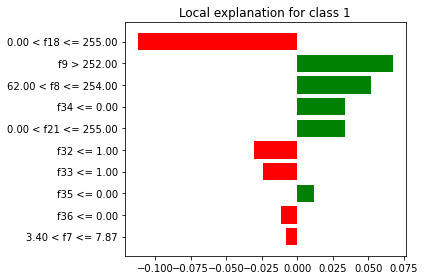

In [20]:
fig = exp.as_pyplot_figure()
plt.tight_layout()
plt.show()